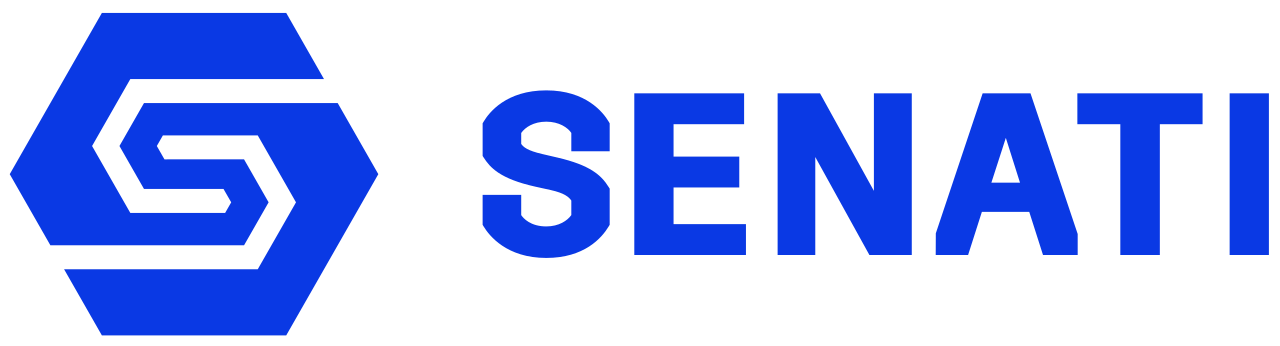

# Caso práctico para estudiantes — 02 RETO LABORATORIO

**Curso:** Machine Learning y Deep Learning  
**Modalidad:** Taller aplicado · **Nivel intermedio guiado**

**Instrucción para el taller:** lee cada explicación, ejecuta una celda y confirma qué cambió antes de continuar.

**Trabajo desarrollado por:** COCA CCORPA LORENA ABIGAIL  
**Institución:** SENATI · 2026  
**Actividad:** Reto 02 — Registros poco habituales de laboratorio  
**Nota:** Los datos suministrados por el taller son simulados; los resultados y pruebas son cálculos realizados sobre esos CSV.

# Reto 02 — Registros poco habituales de laboratorio
Un laboratorio registra horas de uso, cantidad de equipos y consumo. Se desea marcar observaciones distintas del resto para revisarlas.

**Trabajo:** usa Pandas, `StandardScaler` e `IsolationForest(contamination=0.10, random_state=42)`. Cuenta cuántos registros aparecen como poco habituales y crea un formulario Flask. Explica por qué una alerta **no es** diagnóstico de avería.

## Guía para resolver sin perderse
Repite el procedimiento trabajado en el proyecto correspondiente: leer CSV → seleccionar `X` → escalar → entrenar → contar resultados → guardar `modelo_entrenado.joblib` → formulario Flask.

Este reto es **para desarrollar**: el cuaderno contiene apoyos y espacios incompletos, no la solución final.

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto guiado original, paso por paso. Se conserva el enunciado original y el código se ejecuta en orden.</div>

In [1]:
# 1. Leer CSV. Completa el código.
import pandas as pd
datos = pd.read_csv('datos.csv')
print(datos.head())

  registro  horas_uso  equipos  consumo_kwh
0   LAB001        2.5        6         21.1
1   LAB002        1.3        3          7.1
2   LAB003        4.8        3         21.3
3   LAB004        4.8        1          8.8
4   LAB005        8.6        6         55.5


**Columnas a utilizar:** `['horas_uso', 'equipos', 'consumo_kwh']`. Recuerda no incluir la columna que identifica cada registro.

In [2]:
# 2. Separar características y escalar
from sklearn.preprocessing import StandardScaler
COLUMNAS = ['horas_uso', 'equipos', 'consumo_kwh']
X = datos[COLUMNAS]
escalador = StandardScaler()
X_escalada = escalador.fit_transform(X)
print(X_escalada[:3])

[[-1.16744081  1.7224691  -0.18369074]
 [-1.71335715 -0.19839958 -0.97720919]
 [-0.12110116 -0.19839958 -0.17235476]]


Resultados: {-1: 7, 1: 64}
Valores medios por resultado:
           horas_uso  equipos  consumo_kwh
resultado                                 
-1              6.63     4.14        54.59
 1              4.90     3.22        21.03


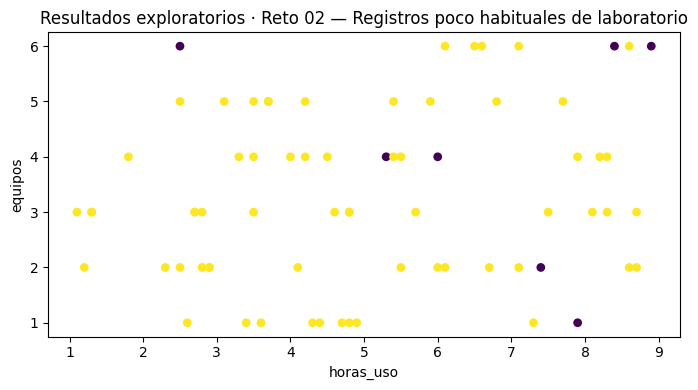

Nuevo caso de prueba: -1


In [3]:
# Entrenamiento reproducible: Reto 02 — Registros poco habituales de laboratorio
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
CARACTERISTICAS = ['horas_uso', 'equipos', 'consumo_kwh']
X = datos[CARACTERISTICAS]
escalador = StandardScaler()
X_escalada = escalador.fit_transform(X)
modelo = IsolationForest(n_estimators=150,contamination=0.09,random_state=42)
resultado = modelo.fit_predict(X_escalada)
datos['resultado'] = resultado
print('Resultados:',datos['resultado'].value_counts().sort_index().to_dict())
print('Valores medios por resultado:')
print(datos.groupby('resultado')[CARACTERISTICAS].mean().round(2))
joblib.dump({'modelo':modelo,'escalador':escalador,'columnas':CARACTERISTICAS,'algoritmo':'isolation'}, 'modelo_entrenado.joblib')
datos.to_csv('resultados.csv',index=False)
plt.figure(figsize=(7,4))
plt.scatter(datos[CARACTERISTICAS[0]],datos[CARACTERISTICAS[1]],c=resultado,cmap='viridis',s=28)
plt.xlabel(CARACTERISTICAS[0]);plt.ylabel(CARACTERISTICAS[1]);plt.title('Resultados exploratorios · '+ 'Reto 02 — Registros poco habituales de laboratorio')
plt.tight_layout();plt.savefig('grafico_resultados.png',dpi=135);plt.show()
print('Nuevo caso de prueba:',modelo.predict(escalador.transform(X.iloc[[0]]))[0])


In [4]:
print('Frecuencias de resultados:')
print(datos['resultado'].value_counts().sort_index())
print('Promedios descriptivos (no atribuir calidad moral a ningún grupo):')
print(datos.groupby('resultado')[CARACTERISTICAS].mean().round(2))

Frecuencias de resultados:
resultado
-1     7
 1    64
Name: count, dtype: int64
Promedios descriptivos (no atribuir calidad moral a ningún grupo):
           horas_uso  equipos  consumo_kwh
resultado                                 
-1              6.63     4.14        54.59
 1              4.90     3.22        21.03


In [5]:
from pathlib import Path
import joblib
joblib.dump({'modelo':modelo,'escalador':escalador,'columnas':CARACTERISTICAS,'algoritmo':'kmeans' if hasattr(modelo,'cluster_centers_') else 'isolation'}, 'modelo_entrenado.joblib')
print('Modelo y escalador exportados')

Modelo y escalador exportados


## Entrega solicitada
- Cuaderno ejecutado con explicación escrita del resultado.
- CSV original y archivo de modelo guardado.
- Carpeta Flask con `app.py`, `templates/index.html`, `static/css/estilos.css`.
- Captura del formulario con dos valores de prueba y explicación.

**Rúbrica (20 puntos):** datos y limpieza (4), entrenamiento explicado (5), interpretación correcta (4), formulario funcional (5), presentación ordenada (2).

### Respuestas cortas

1. **¿Qué buscamos?** Lecturas que se alejan de lo habitual.
2. **¿Qué usamos?** Horas, equipos y consumo de energía.
3. **¿Por qué escalar?** Para comparar variables con unidades distintas.
4. **¿Qué significa -1?** Registro atípico para revisar, no avería confirmada.
5. **Límite:** una lectura rara puede ser normal según el contexto.

### Interpretación de pruebas y límites del algoritmo

In [6]:
paquete=joblib.load('modelo_entrenado.joblib')
filas=datos[CARACTERISTICAS].iloc[:2].copy()
filas['prediccion']=paquete['modelo'].predict(paquete['escalador'].transform(filas))
print(filas.to_string(index=False))

 horas_uso  equipos  consumo_kwh  prediccion
       2.5        6         21.1          -1
       1.3        3          7.1           1


**Isolation Forest:** La salida `-1` indica una observación poco habitual según el modelo y los datos educativos, no un error, avería ni peligro confirmado. Verifica esos casos antes de concluir. El escalador utilizado al predecir es **exactamente el entrenado**; estos CSV son simulados.